# Task 1 Exploratory Data Analysis

Explore the stroke dataset in the order used by `00_data_exploration.py`, then inspect missing values, outcome differences and correlations. Run **all cells from top to bottom**. The notebook displays results and saves the figures used in the Word report under `output/task1/`. The supplied EDA script and helper are preserved; notebook paths are adapted for this submission.

Install `requirements.txt` and select the resulting Python environment as the notebook kernel. See `README.md` for setup instructions.

In [1]:
from pathlib import Path
import sys
import io
import json
import contextlib
import os
import runpy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

# Locate the dataset from the submission folder.
candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in candidates if (p / 'data/healthcare-dataset-stroke-data.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Download the dataset into data/ and open this notebook from the submission folder.')
PROJECT = ROOT
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from utils import DataLoader

OUT = ROOT / 'output/task1'
FIG = OUT / 'figures'
SOURCE_OUT = OUT / 'source_outputs'
for folder in [OUT, FIG, SOURCE_OUT]:
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white'})
BLUE, ORANGE = '#386A8A', '#C37839'
num = ['age', 'avg_glucose_level', 'bmi']
cat = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
labels = ['Age (years)', 'Average glucose level (dataset units)', 'BMI']

def save(fig, name):
    fig.savefig(FIG / name, dpi=220, bbox_inches='tight', facecolor='white')
    display(fig)
    plt.close(fig)

loader = DataLoader()
loader.load_dataset(PROJECT / 'data/healthcare-dataset-stroke-data.csv')
data = loader.data.copy()
df = data  # Short alias used in the plotting cells.
print('Dataset:', PROJECT / 'data/healthcare-dataset-stroke-data.csv')

Dataset: /Users/benjy/UM/XAI/Assignment1/XAI_Assign1_Submission_Benjy/data/healthcare-dataset-stroke-data.csv


## 1 Dataset shape and preview

`shape` reports rows and columns. `head()` displays the first five records, including the missing BMI in Row 1. The preview is not a random sample; all five rows having stroke = 1 does not describe the full class balance. Report Figures 1a and 1b use these records.

In [2]:
print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 2 Column types and missing information

`info()` shows column types and non-null counts. BMI has fewer observed values. The text category `Unknown` is not a pandas null, so smoking history needs a separate check. Report Figure 2 uses this output.

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [4]:
quality = pd.DataFrame({
    'missing_count': data.isna().sum(),
    'missing_percent': data.isna().mean().mul(100).round(2)
})
display(quality)
print('Duplicate rows:', data.duplicated().sum())
print('Duplicate identifiers:', data['id'].duplicated().sum())
unknown = data['smoking_status'].eq('Unknown').sum()
print(f'Unknown smoking history: {unknown:,} ({unknown / len(data):.2%})')
missing_by_outcome = data.groupby('stroke')['bmi'].agg(
    records='size', observed='count')
missing_by_outcome['missing'] = missing_by_outcome['records'] - missing_by_outcome['observed']
missing_by_outcome['missing_percent'] = (100 * missing_by_outcome['missing'] / missing_by_outcome['records']).round(2)
display(missing_by_outcome)

,missing_count,missing_percent
id,0,0.00
gender,0,0.00
age,0,0.00
hypertension,0,0.00
heart_disease,0,0.00
ever_married,0,0.00
work_type,0,0.00
Residence_type,0,0.00
avg_glucose_level,0,0.00
bmi,201,3.93


Duplicate rows: 0
Duplicate identifiers: 0
Unknown smoking history: 1,544 (30.22%)


,records,observed,missing,missing_percent
stroke,,,,
0,4861,4700,161,3.31
1,249,209,40,16.06


## 3 Numerical and categorical summaries

`describe()` adds counts, means, quartiles and ranges to the supplied script. Missing BMI is excluded only from calculations requiring BMI; no whole records are dropped. Report Table 1 shows the continuous columns.

In [5]:
display(data.describe())

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [6]:
display(data.describe(include="object"))

,gender,ever_married,work_type,Residence_type,smoking_status
count,5110,5110,5110,5110,5110
unique,3,2,5,2,4
top,Female,Yes,Private,Urban,never smoked
freq,2994,3353,2925,2596,1892


## 4 Histograms

The following uses the same `data[col].hist()` operation and default 10 bins as the supplied script, arranging three informative columns together. These are Report Figure 3. The identifier does not describe a patient characteristic and is omitted here; the complete original loop is executed in Section 10.

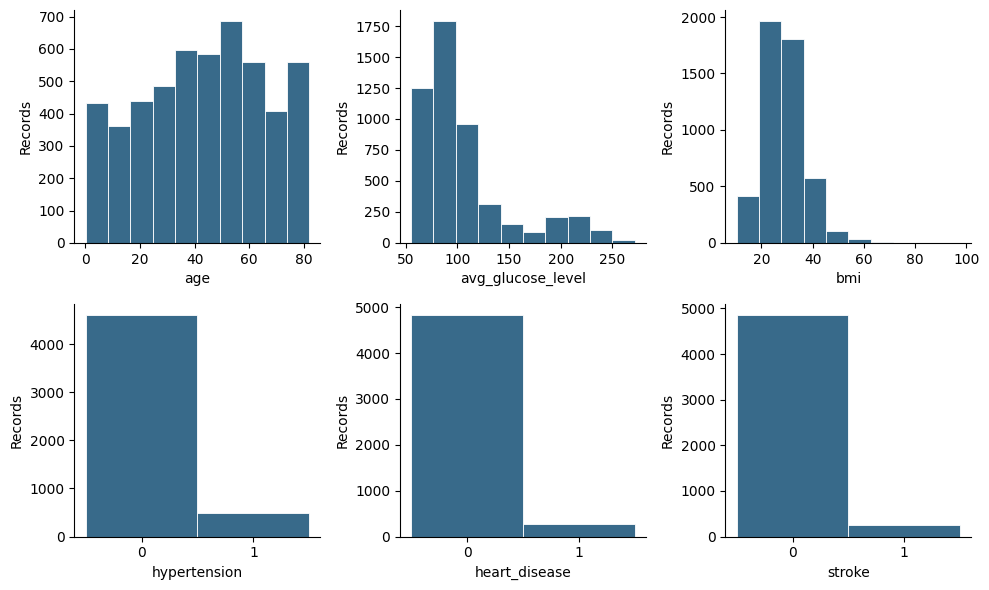

In [26]:
fig,axes=plt.subplots(2,3,figsize=(10,6))
for ax,col in zip(axes[0],['age','avg_glucose_level','bmi']):
  df[col].hist(ax=ax,color='#386A8A',edgecolor='white',linewidth=.6)
  ax.set_xlabel(col);ax.set_ylabel('Records');ax.grid(False)
for ax,col in zip(axes[1],['hypertension','heart_disease','stroke']):
  df[col].hist(ax=ax,bins=[-.5,.5,1.5],color='#386A8A',edgecolor='white',linewidth=.6)
  ax.set_xticks([0,1]);ax.set_xlabel(col);ax.set_ylabel('Records');ax.grid(False)
fig.tight_layout()
save(fig, '09_source_histograms.png')

Age covers children and adults. Glucose and BMI have upper tails, so their medians are useful alongside their means. Extreme observations warrant review but are not automatically errors.

## 5 Categorical distributions and class balance

Category counts identify common and poorly represented groups. The outcome counts reveal severe imbalance. Report Figures 4 and 5 use these plots.

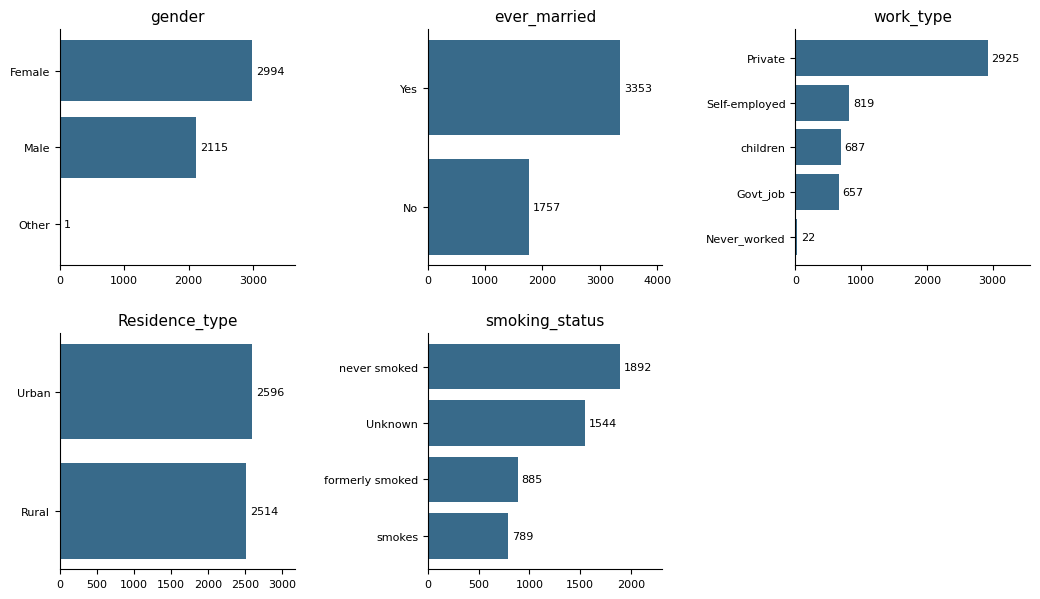

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.1))
for ax,col in zip(axes.flat,cat):
    v=df[col].value_counts()
    y=np.arange(len(v))
    ax.barh(y,v.values,color=BLUE)
    ax.set_yticks(y, v.index); ax.invert_yaxis(); ax.set_title(col, fontsize=11)
    ax.set_xlim(0,v.max()*1.22)
    for j,n in enumerate(v): ax.text(n+v.max()*.02,j,str(n),va='center',fontsize=8)
    ax.tick_params(axis='both',labelsize=8)
axes.flat[-1].axis('off')
fig.tight_layout(w_pad=2,h_pad=2); save(fig,'02_categorical_counts.png')

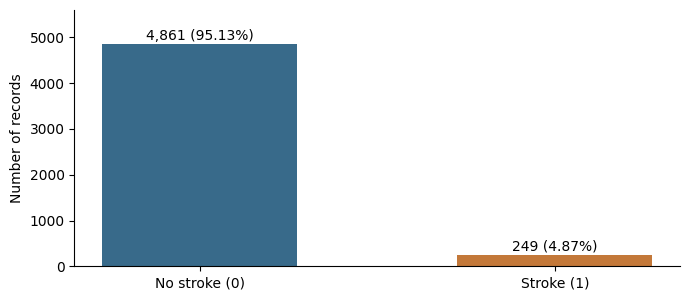

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.1))
counts = df['stroke'].value_counts().reindex([0,1])
bars = ax.bar(['No stroke (0)', 'Stroke (1)'], counts, color=[BLUE, ORANGE], width=.55)
for b,v in zip(bars, counts):
    ax.text(b.get_x()+b.get_width()/2, v+90, f'{v:,} ({100*v/len(df):.2f}%)', ha='center')
ax.set_ylim(0, 5600); ax.set_ylabel('Number of records')
fig.tight_layout(); save(fig, '01_stroke_balance.png')

In [10]:
balance = data['stroke'].value_counts().sort_index().rename('count').to_frame()
balance['percent'] = balance['count'].div(len(data)).mul(100)
display(balance)
print(f'Always predicting no stroke would give {100 * data.stroke.eq(0).mean():.2f}% accuracy and 0% stroke recall.')

,count,percent
stroke,,
0,4861,95.127202
1,249,4.872798


Always predicting no stroke would give 95.13% accuracy and 0% stroke recall.


## 6 Compare stroke and no-stroke records

Boxplots show medians, the middle 50% of observations, spread and potential outliers. They compare distributions rather than prove causation. Report Figure 6 and Table 2 use these results.

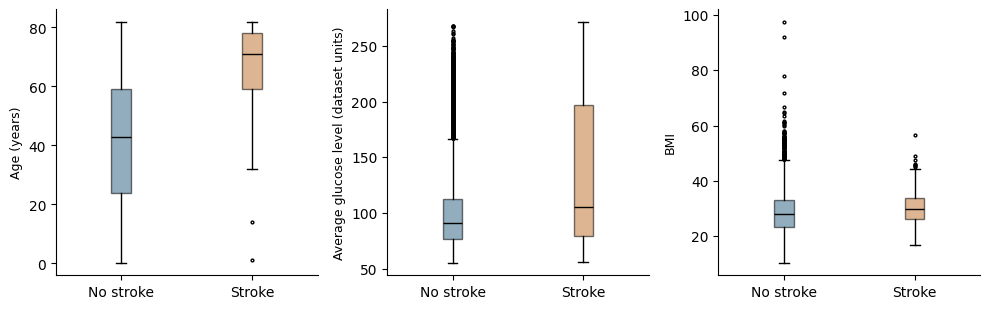

In [11]:
fig, axes = plt.subplots(1,3,figsize=(10,3.2))
for ax,col,label in zip(axes,num,labels):
    bp=ax.boxplot([df.loc[df.stroke==s,col].dropna() for s in [0,1]],patch_artist=True,medianprops={'color':'black'},flierprops={'markersize':2})
    for patch,color in zip(bp['boxes'],[BLUE,ORANGE]): patch.set_facecolor(color); patch.set_alpha(.55)
    ax.set_xticks([1,2],['No stroke','Stroke']); ax.set_ylabel(label,fontsize=9)
fig.tight_layout(); save(fig,'05_outcome_comparisons.png')

In [12]:
display(data.groupby('stroke')[num].agg(['count', 'mean', 'median']))
for column in ['hypertension', 'heart_disease', 'smoking_status']:
    rates = data.groupby(column)['stroke'].agg(records='size', stroke_records='sum')
    rates['stroke_percent'] = (100 * rates['stroke_records'] / rates['records']).round(2)
    print(column)
    display(rates)

age                   avg_glucose_level                       bmi  \
       count       mean median             count        mean  median count   
stroke                                                                       
0       4861  41.971545   43.0              4861  104.795513   91.47  4700   
1        249  67.728193   71.0               249  132.544739  105.22   209   

                          
             mean median  
stroke                    
0       28.823064   28.0  
1       30.471292   29.7

hypertension


,records,stroke_records,stroke_percent
hypertension,,,
0,4612,183,3.97
1,498,66,13.25


heart_disease


,records,stroke_records,stroke_percent
heart_disease,,,
0,4834,202,4.18
1,276,47,17.03


smoking_status


,records,stroke_records,stroke_percent
smoking_status,,,
Unknown,1544,47,3.04
formerly smoked,885,70,7.91
never smoked,1892,90,4.76
smokes,789,42,5.32


Stroke records have a median age of 71 versus 43 for no-stroke records. Glucose is also higher in the stroke group, while BMI overlaps more. BMI comparisons use only observed measurements, with different amounts of missingness in each group.

## 7 Inspect the original preprocessing

Run the supplied helper on a separate copy. It one-hot encodes five categorical columns, removes `id`, and fills missing BMI with zero. The original measurements in `data` remain available for EDA. The zero replacement is reproduced to explain the supplied code; a training-fitted median imputer is planned for modelling. Report Figure 7 displays these records transposed.

In [13]:
original_loader = DataLoader()
original_loader.data = data.copy(deep=True)
original_loader.preprocess_data()
processed = original_loader.data
print('Before preprocessing:', data.shape)
print('After original preprocessing:', processed.shape)
print('Artificial zero BMI values:', processed['bmi'].eq(0).sum())
display(processed.head())

Before preprocessing: (5110, 12)
After original preprocessing: (5110, 22)
Artificial zero BMI values: 201


,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
0,False,True,False,False,True,False,False,True,False,False,False,True,False,True,False,False,67.0,0,1,228.69,36.6,1
1,True,False,False,False,True,False,False,False,True,False,True,False,False,False,True,False,61.0,0,0,202.21,0.0,1
2,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True,False,80.0,0,1,105.92,32.5,1
3,True,False,False,False,True,False,False,True,False,False,False,True,False,False,False,True,49.0,0,0,171.23,34.4,1
4,True,False,False,False,True,False,False,False,True,False,True,False,False,False,True,False,79.0,1,0,174.12,24.0,1


In [14]:
display(processed.head().T)
print('Row 1 BMI before:', data.loc[1, 'bmi'])
print('Row 1 BMI after:', processed.loc[1, 'bmi'])

,0,1,2,3,4
gender_Female,False,True,False,True,True
gender_Male,True,False,True,False,False
gender_Other,False,False,False,False,False
ever_married_No,False,False,False,False,False
ever_married_Yes,True,True,True,True,True
work_type_Govt_job,False,False,False,False,False
work_type_Never_worked,False,False,False,False,False
work_type_Private,True,False,True,True,False
work_type_Self-employed,False,True,False,False,True
work_type_children,False,False,False,False,False


Row 1 BMI before: nan
Row 1 BMI after: 0.0


## 8 Correlation heatmap

Pearson correlation summarizes pairwise linear associations for the numeric variables. BMI pairs use 4,909 records; other pairs use 5,110. Correlation is not model feature importance, and a small coefficient does not rule out nonlinear effects. Report Figure 8 uses this plot.

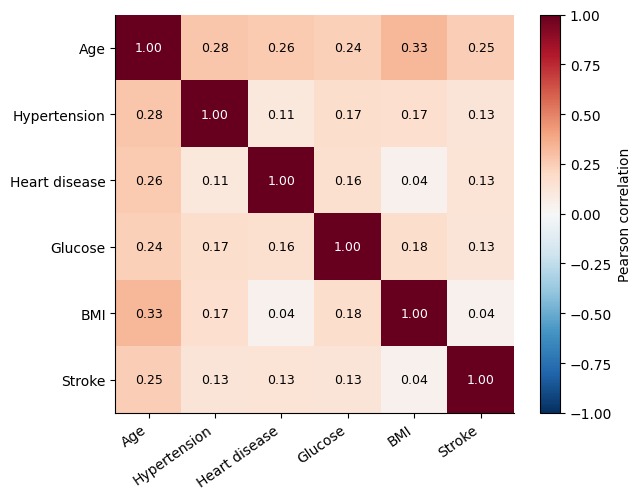

In [15]:
cols=['age','hypertension','heart_disease','avg_glucose_level','bmi','stroke']
corr=df[cols].corr()
corr.to_csv(OUT/'numeric_correlations.csv')
fig,ax=plt.subplots(figsize=(7.5,5.1))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(len(cols)),['Age','Hypertension','Heart disease','Glucose','BMI','Stroke'],rotation=35,ha='right')
ax.set_yticks(range(len(cols)),['Age','Hypertension','Heart disease','Glucose','BMI','Stroke'])
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9,color='white' if abs(corr.iloc[i,j])>.6 else 'black')
fig.colorbar(im,ax=ax,label='Pearson correlation',fraction=.045,pad=.04)
fig.tight_layout(); save(fig,'06_correlation_heatmap.png')

In [16]:
display(corr['stroke'].drop('stroke').sort_values(ascending=False))

age                  0.245257
heart_disease        0.134914
avg_glucose_level    0.131945
hypertension         0.127904
bmi                  0.042374
Name: stroke, dtype: float64

## 9 Save numerical results

CSV and JSON outputs make the values in the report easy to check. All summaries below use the original observed data.

In [17]:
df.describe().to_csv(OUT / 'numeric_summary.csv')
df.describe(include='object').to_csv(OUT / 'categorical_summary.csv')
df.isna().sum().rename('missing_count').to_csv(OUT / 'missing_values.csv')
df.groupby('stroke')[num].agg(['count', 'mean', 'median']).to_csv(OUT / 'outcome_summary.csv')
for col in ['hypertension', 'heart_disease', 'smoking_status']:
    g=df.groupby(col)['stroke'].agg(['count','sum','mean'])
    g.rename(columns={'sum':'stroke_count','mean':'stroke_proportion'}).to_csv(OUT/f'{col}_stroke_rates.csv')

stats={'rows':len(df),'columns':len(df.columns),'duplicates':int(df.duplicated().sum()),
       'duplicate_ids':int(df.id.duplicated().sum()),'missing_bmi':int(df.bmi.isna().sum()),
       'unknown_smoking':int(df.smoking_status.eq('Unknown').sum()),
       'numeric':df[num].describe().to_dict(),
       'target_counts':df.stroke.value_counts().to_dict(),
       'category_counts':{c:df[c].value_counts().to_dict() for c in cat},
       'stroke_correlations':corr.stroke.to_dict()}
(OUT/'eda_results.json').write_text(json.dumps(stats,indent=2))

print('Numerical results saved to:', OUT)

Numerical results saved to: /Users/benjy/UM/XAI/Assignment1/XAI_Assign1_Submission_Benjy/output/task1


## 10 Execute the complete supplied script

The original `00_data_exploration.py` is also executed unchanged. Its 12 histogram windows are saved as PNG files rather than opened separately. `head()` expressions in a plain script do not print automatically; their results are displayed explicitly in Sections 1 and 7 above. This execution does not replace the notebook data.

In [18]:
# Execute the supplied script, saving each figure instead of opening UI windows.
old_cwd=Path.cwd()
count=[0]
def save_show(*args,**kwargs):
  count[0]+=1
  plt.gcf().savefig(SOURCE_OUT/f'original_histogram_{count[0]:02d}.png',dpi=150,bbox_inches='tight')
  plt.close('all')
old_show=plt.show
try:
  os.chdir(PROJECT)
  plt.show=save_show
  with (SOURCE_OUT/'original_script_execution.txt').open('w') as f,contextlib.redirect_stdout(f):
    runpy.run_path('00_data_exploration.py',run_name='__main__')
finally:
  plt.show=old_show
  os.chdir(old_cwd)

print(f'Original script completed; {count[0]} histogram files saved.')
print((SOURCE_OUT / 'original_script_execution.txt').read_text())

Original script completed; 12 histogram files saved.
(5110, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
col:  id
col:  gender
col:  age
col:  hypertension
col:  heart_disease
col:  ever_married
col

## 11 Export the dataframe images used in Word

The report uses formatted images of the same `head()` and `info()` results. This optional export section recreates those images without changing the CSV. The cell is collapsed because it concerns report formatting rather than statistical interpretation.

In [19]:
loader=DataLoader()
loader.load_dataset(PROJECT / 'data/healthcare-dataset-stroke-data.csv')
df=loader.data.copy()
buf=io.StringIO(); df.info(buf=buf)
info=buf.getvalue()
(SOURCE_OUT/'data_info.txt').write_text(info)
(SOURCE_OUT/'data_shape.txt').write_text(str(df.shape))
(SOURCE_OUT/'data_head.txt').write_text(df.head().to_string())
(SOURCE_OUT/'data_describe.txt').write_text(df.describe().to_string())
df.head().to_csv(SOURCE_OUT/'data_head.csv',index=True)
loader.preprocess_data()
processed=loader.data
(SOURCE_OUT/'preprocessed_head.txt').write_text(processed.head().to_string())
processed.head().to_csv(SOURCE_OUT/'preprocessed_head.csv',index=True)
(SOURCE_OUT/'preprocessing_checks.txt').write_text(f'Before: {df.shape}\nAfter: {processed.shape}\nMissing BMI before: {df.bmi.isna().sum()}\nMissing BMI after: {processed.bmi.isna().sum()}\nZero BMI after: {processed.bmi.eq(0).sum()}\n')

# The first five records are displayed in two panels for legible column names.
for part,cols in enumerate([df.columns[:6],df.columns[6:]],1):
  subset=df.loc[:4,cols].copy()
  labels=list(cols)
  
  # Wrap long column names without changing their meaning.
  labels=[s.replace('heart_disease','heart_\ndisease').replace('ever_married','ever_\nmarried').replace('Residence_type','Residence_\ntype').replace('avg_glucose_level','avg_glucose_\nlevel').replace('smoking_status','smoking_\nstatus') for s in labels]
  cells=[[str(i)]+[str(v) for v in row] for i,row in zip (subset.index,subset.values)]
  fig,ax=plt.subplots(figsize=(10,1.75)); ax.axis('off')
  widths=[.045,.13,.17,.15,.17,.17,.165] if part==1 else [.045,.17,.17,.18,.10,.235,.10]
  tab=ax.table(cellText=cells,colLabels=['Row']+labels,cellLoc='center',colLoc='center',colWidths=widths,loc='center')
  tab.auto_set_font_size(False); tab.set_fontsize(10.5); tab.scale(1,1.35)
  for (r,c),cell in tab.get_celld().items():
    cell.set_edgecolor('#CCCCCC'); cell.set_linewidth(.5)
    if r==0:cell.set_facecolor('#E7E6E6'); cell.set_text_props(weight='bold'); cell.set_height(cell.get_height()*1.5)
  fig.savefig(FIG/f'07_head_part{part}.png',dpi=220,bbox_inches='tight',pad_inches=.03); plt.close(fig)
fig,ax=plt.subplots(figsize=(8.4,3.7)); ax.axis('off')
ax.text(0,1,info,va='top',family='DejaVu Sans Mono',fontsize=10.4,linespacing=1.18)
fig.savefig(FIG/'08_data_info.png',dpi=220,bbox_inches='tight',pad_inches=.04); plt.close(fig)

# Display all five processed records transposed to fit all 22 columns legibly.
t=processed.head().T
fig,ax=plt.subplots(figsize=(10,7.2));ax.axis('off')
cells=[[str(idx)]+[str(v) for v in row] for idx,row in zip(t.index,t.values)]
tab=ax.table(cellText=cells,colLabels=['Processed column','Row 0','Row 1','Row 2','Row 3','Row 4'],colWidths=[.47,.106,.106,.106,.106,.106],cellLoc='center',loc='center')
tab.auto_set_font_size(False);tab.set_fontsize(10.5);tab.scale(1,1.48)
for (r,c),cell in tab.get_celld().items():
  cell.set_edgecolor('#D9D9D9');cell.set_linewidth(.5)
  if c==0:cell.set_text_props(ha='left')
  if r==0:cell.set_facecolor('#E7E6E6');cell.set_text_props(weight='bold')
fig.savefig(FIG/'10_preprocessed_head.png',dpi=220,bbox_inches='tight',pad_inches=.03);plt.close(fig)

print('Report dataframe images saved to:', FIG)

Report dataframe images saved to: /Users/benjy/UM/XAI/Assignment1/XAI_Assign1_Submission_Benjy/output/task1/figures


## Key findings

- There are 5,110 records; only 249 (4.87%) are stroke cases.
- BMI is missing for 201 records, with more missingness in the stroke group.
- Smoking history is Unknown for 1,544 records.
- Age shows the clearest outcome-group difference; glucose and BMI have upper tails.
- The original zero-filling of BMI needs improvement before modelling.
- Use a stratified split, training-fitted preprocessing, and training-only resampling for later tasks.